In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

In [8]:
FILE = "3TIE_10_KinerjaAkademikMahasiswa.xlsx"
df = pd.read_excel(FILE, sheet_name="Data")
ket = pd.read_excel(FILE, sheet_name="Keterangan Variabel")

print("Jumlah baris & kolom:", df.shape)
print(df.head())

Jumlah baris & kolom: (7000, 25)
   Student_ID  Age  Gender  Course_Year  Attendance_Percentage  Assignment_Submission_Rate  Quiz_Average_Score  Midterm_Score  Previous_GPA  Online_Learning_Hours  Course_Participation_Score  \
0           1   23    Male            2                  76.35                       42.02               35.15          48.41          3.59                   6.75                       79.29   
1           2   20  Female            1                  69.88                       38.63               82.98          24.43          2.07                  13.70                       33.82   
2           3   24  Female            2                  83.69                       44.27               28.15          59.40          1.58                   8.32                       88.91   
3           4   21    Male            1                  50.28                       89.93               42.66          50.83          2.59                  12.50                       54.33 

In [9]:
print(df.info())
print("\nMissing value per kolom:\n", df.isna().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())
print("\nKeterangan variabel:\n", ket[["Nama Variabel", "Tipe Data",
                                       "Skala Pengukuran"]])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Student_ID                       7000 non-null   int64  
 1   Age                              7000 non-null   int64  
 2   Gender                           7000 non-null   object 
 3   Course_Year                      7000 non-null   int64  
 4   Attendance_Percentage            7000 non-null   float64
 5   Assignment_Submission_Rate       7000 non-null   float64
 6   Quiz_Average_Score               7000 non-null   float64
 7   Midterm_Score                    7000 non-null   float64
 8   Previous_GPA                     7000 non-null   float64
 9   Online_Learning_Hours            7000 non-null   float64
 10  Course_Participation_Score       7000 non-null   float64
 11  Forum_Activity_Count             7000 non-null   int64  
 12  Login_Frequency_Per_

In [10]:
var_utama = ["Online_Learning_Hours", "Login_Frequency_Per_Week",
             "Forum_Activity_Count", "Learning_Resource_Access_Count"]
var_disiplin = ["Attendance_Percentage", "Assignment_Submission_Rate",
                "Late_Submission_Count", "Missing_Assignment_Count"]
var_capaian = ["Quiz_Average_Score", "Midterm_Score", "Performance_Score",
               "Final_Academic_Score"]
var_kategorik = ["Gender", "Course_Year", "Academic_Risk_Level",
                 "Intervention_Recommendation"]
var_numerik = var_utama + var_disiplin + var_capaian

In [11]:
for v in var_kategorik:
    frek = df[v].value_counts().sort_index()
    tabel = pd.DataFrame({"Frekuensi": frek,
                          "Persen (%)": (frek / len(df) * 100).round(2)})
    print(f"\n=== {v} ===\n{tabel}")


=== Gender ===
        Frekuensi  Persen (%)
Gender                       
Female       3397       48.53
Male         3603       51.47

=== Course_Year ===
             Frekuensi  Persen (%)
Course_Year                       
1                 1981       28.30
2                 1890       27.00
3                 1678       23.97
4                 1451       20.73

=== Academic_Risk_Level ===
                     Frekuensi  Persen (%)
Academic_Risk_Level                       
High Risk                 1523       21.76
Low Risk                  1819       25.99
Medium Risk               3658       52.26

=== Intervention_Recommendation ===
                                  Frekuensi  Persen (%)
Intervention_Recommendation                            
Academic Counseling and Tutoring       1523       21.76
Adaptive Learning Resources            3658       52.26
Regular Monitoring                     1819       25.99


In [12]:
def tabel_frekuensi(seri):
    k = int(np.ceil(1 + 3.322 * np.log10(len(seri))))   # jumlah kelas
    kelas = pd.cut(seri, bins=k)
    f = kelas.value_counts().sort_index()
    out = pd.DataFrame({"Frekuensi": f,
                        "Frek. Relatif (%)": (f / f.sum() * 100).round(2),
                        "Frek. Kumulatif": f.cumsum()})
    return out

print("Online_Learning_Hours\n", tabel_frekuensi(df["Online_Learning_Hours"]))
print("\nFinal_Academic_Score\n", tabel_frekuensi(df["Final_Academic_Score"]))

Online_Learning_Hours
                        Frekuensi  Frek. Relatif (%)  Frek. Kumulatif
Online_Learning_Hours                                               
(0.486, 1.536]               488               6.97              488
(1.536, 2.571]               480               6.86              968
(2.571, 3.607]               526               7.51             1494
(3.607, 4.643]               522               7.46             2016
(4.643, 5.679]               519               7.41             2535
(5.679, 6.714]               470               6.71             3005
(6.714, 7.75]                483               6.90             3488
(7.75, 8.786]                476               6.80             3964
(8.786, 9.821]               469               6.70             4433
(9.821, 10.857]              502               7.17             4935
(10.857, 11.893]             530               7.57             5465
(11.893, 12.929]             522               7.46             5987
(12.929, 13

In [13]:
def deskriptif(seri):
    q1, q3 = seri.quantile(0.25), seri.quantile(0.75)
    return pd.Series({
        "N": seri.count(),
        "Mean": seri.mean(),
        "Median": seri.median(),
        "Modus": seri.mode().iloc[0],
        "Std Dev": seri.std(),
        "Varians": seri.var(),
        "Min": seri.min(),
        "Q1": q1,
        "Q3": q3,
        "Max": seri.max(),
        "Range": seri.max() - seri.min(),
        "IQR": q3 - q1,
        "Skewness": seri.skew(),
        "Kurtosis": seri.kurt(),
    })

stat = df[var_numerik].apply(deskriptif).T.round(2)
print(stat)

                                     N   Mean  Median   Modus  Std Dev  Varians    Min     Q1     Q3     Max   Range    IQR  Skewness  Kurtosis
Online_Learning_Hours           7000.0   7.79    7.77    2.98     4.20    17.67   0.50   4.14  11.49   15.00   14.50   7.35     -0.01     -1.23
Login_Frequency_Per_Week        7000.0   7.53    8.00   14.00     4.06    16.51   1.00   4.00  11.00   14.00   13.00   7.00     -0.01     -1.22
Forum_Activity_Count            7000.0  22.22   22.00   32.00    13.08   171.00   0.00  11.00  34.00   44.00   44.00  23.00     -0.03     -1.21
Learning_Resource_Access_Count  7000.0  40.35   40.00   10.00    22.62   511.69   2.00  21.00  60.00   79.00   77.00  39.00      0.02     -1.21
Attendance_Percentage           7000.0  67.65   67.70   47.65    18.79   353.09  35.00  51.51  84.02   99.99   64.99  32.51     -0.01     -1.22
Assignment_Submission_Rate      7000.0  60.09   60.35   59.22    23.07   532.00  20.01  40.38  80.03  100.00   79.99  39.65     -0.01   

In [14]:
outlier = {}
for v in var_numerik:
    q1, q3 = df[v].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier[v] = ((df[v] < batas_bawah) | (df[v] > batas_atas)).sum()
print(pd.Series(outlier, name="Jumlah Outlier"))

Online_Learning_Hours              0
Login_Frequency_Per_Week           0
Forum_Activity_Count               0
Learning_Resource_Access_Count     0
Attendance_Percentage              0
Assignment_Submission_Rate         0
Late_Submission_Count              0
Missing_Assignment_Count           0
Quiz_Average_Score                 0
Midterm_Score                      0
Performance_Score                 14
Final_Academic_Score              16
Name: Jumlah Outlier, dtype: int64


In [15]:
print(df.groupby("Academic_Risk_Level")[var_utama + ["Final_Academic_Score"]]
        .agg(["mean", "median", "std"]).round(2))

print(df.groupby("Course_Year")[["Online_Learning_Hours",
                                 "Final_Academic_Score"]]
        .agg(["mean", "median", "std"]).round(2))

print(df.groupby("Gender")[["Online_Learning_Hours",
                            "Final_Academic_Score"]]
        .agg(["mean", "median", "std"]).round(2))

                    Online_Learning_Hours              Login_Frequency_Per_Week              Forum_Activity_Count               Learning_Resource_Access_Count               Final_Academic_Score  \
                                     mean median   std                     mean median   std                 mean median    std                           mean median    std                 mean   
Academic_Risk_Level                                                                                                                                                                                 
High Risk                            6.16   5.45  3.98                     7.04    7.0  4.06                21.98   22.0  13.23                          38.32   37.0  22.51                37.04   
Low Risk                             9.13   9.89  4.07                     8.24    9.0  4.03                22.42   23.0  13.00                          42.77   44.0  22.35                76.90   
Medium Risk    

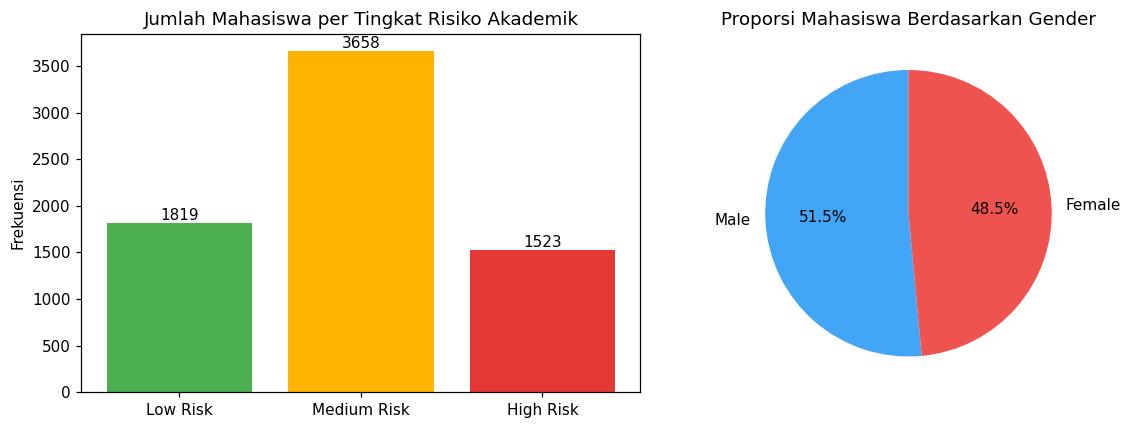

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
urut = ["Low Risk", "Medium Risk", "High Risk"]
jml = df["Academic_Risk_Level"].value_counts().reindex(urut)
ax[0].bar(urut, jml.values, color=["#4caf50", "#ffb300", "#e53935"])
ax[0].set_title("Jumlah Mahasiswa per Tingkat Risiko Akademik")
ax[0].set_ylabel("Frekuensi")
for i, v in enumerate(jml.values):
    ax[0].text(i, v + 30, str(v), ha="center")

gender = df["Gender"].value_counts()
ax[1].pie(gender.values, labels=gender.index, autopct="%1.1f%%",
          startangle=90, colors=["#42a5f5", "#ef5350"])
ax[1].set_title("Proporsi Mahasiswa Berdasarkan Gender")
plt.tight_layout()
plt.savefig("viz_01_kategorik.png")
plt.show()

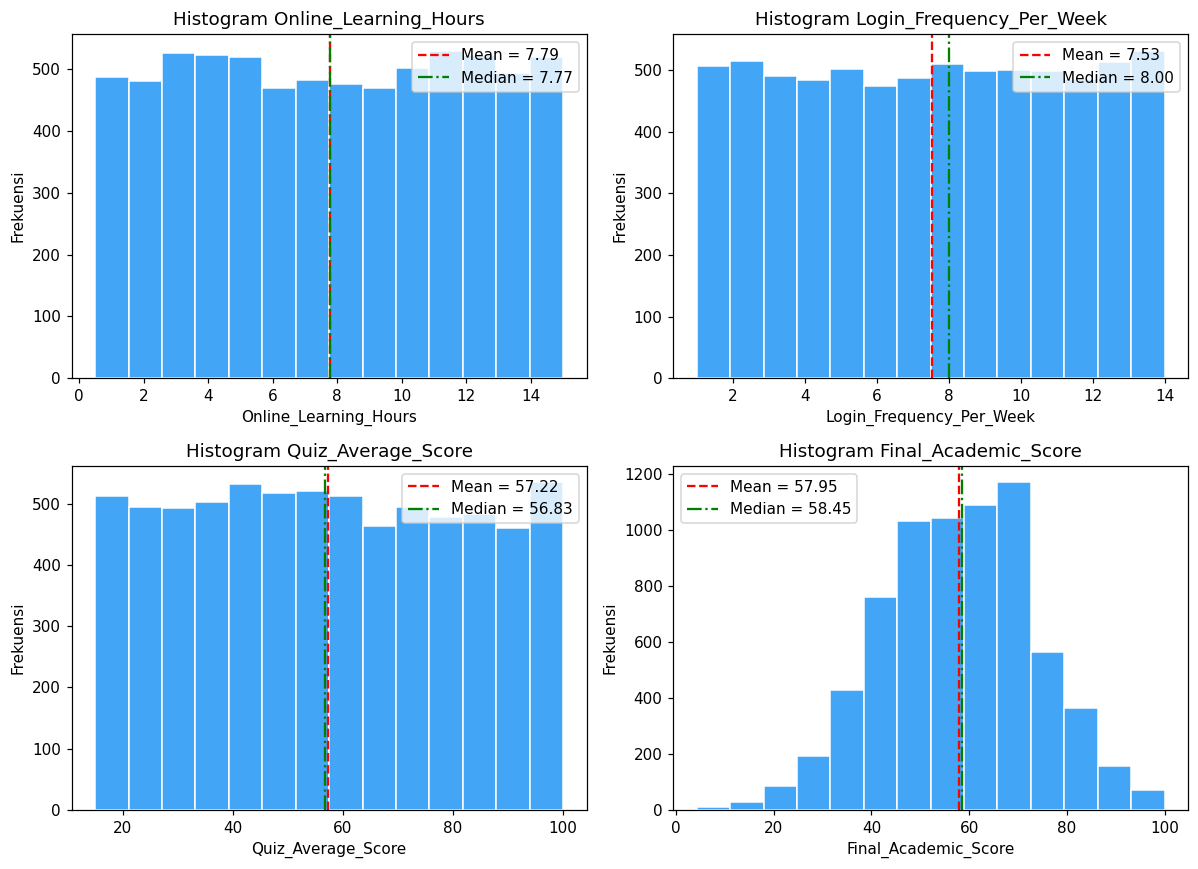

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, v in zip(ax.ravel(), ["Online_Learning_Hours",
                             "Login_Frequency_Per_Week",
                             "Quiz_Average_Score",
                             "Final_Academic_Score"]):
    a.hist(df[v], bins=14, color="#42a5f5", edgecolor="white")
    a.axvline(df[v].mean(), color="red", ls="--",
              label=f"Mean = {df[v].mean():.2f}")
    a.axvline(df[v].median(), color="green", ls="-.",
              label=f"Median = {df[v].median():.2f}")
    a.set_title(f"Histogram {v}")
    a.set_xlabel(v)
    a.set_ylabel("Frekuensi")
    a.legend()
plt.tight_layout()
plt.savefig("viz_02_histogram.png")
plt.show()

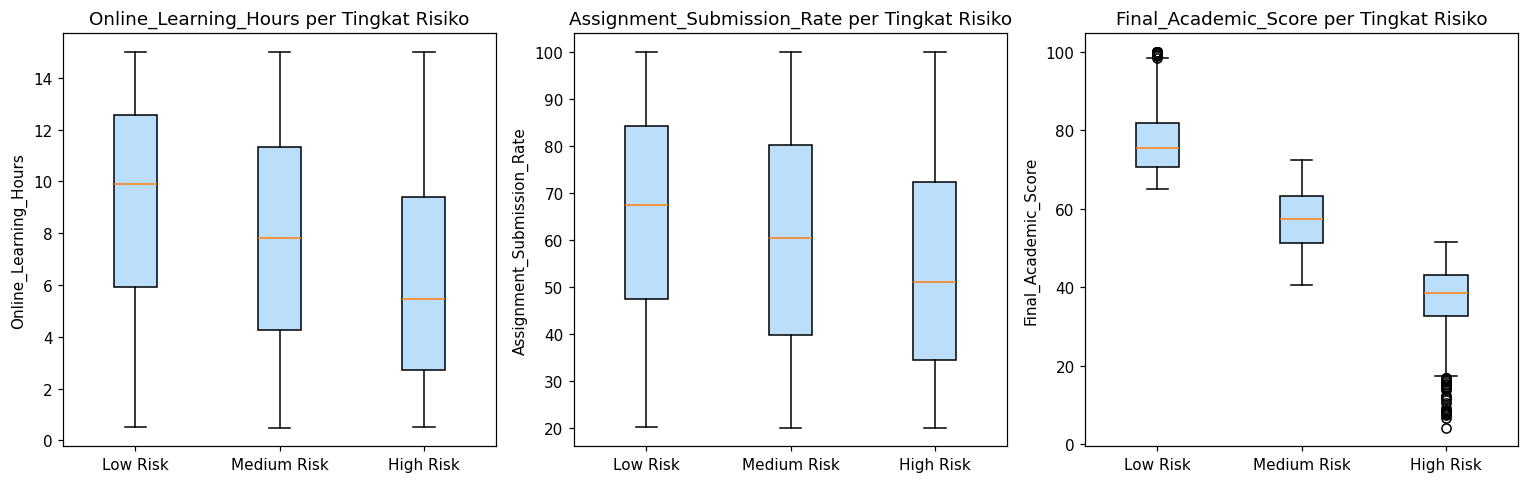

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
for a, v in zip(ax, ["Online_Learning_Hours",
                     "Assignment_Submission_Rate",
                     "Final_Academic_Score"]):
    data = [df.loc[df["Academic_Risk_Level"] == r, v] for r in urut]
    a.boxplot(data, patch_artist=True,
              boxprops=dict(facecolor="#bbdefb"))
    a.set_xticklabels(urut)
    a.set_title(f"{v} per Tingkat Risiko")
    a.set_ylabel(v)
plt.tight_layout()
plt.savefig("viz_03_boxplot.png")
plt.show()

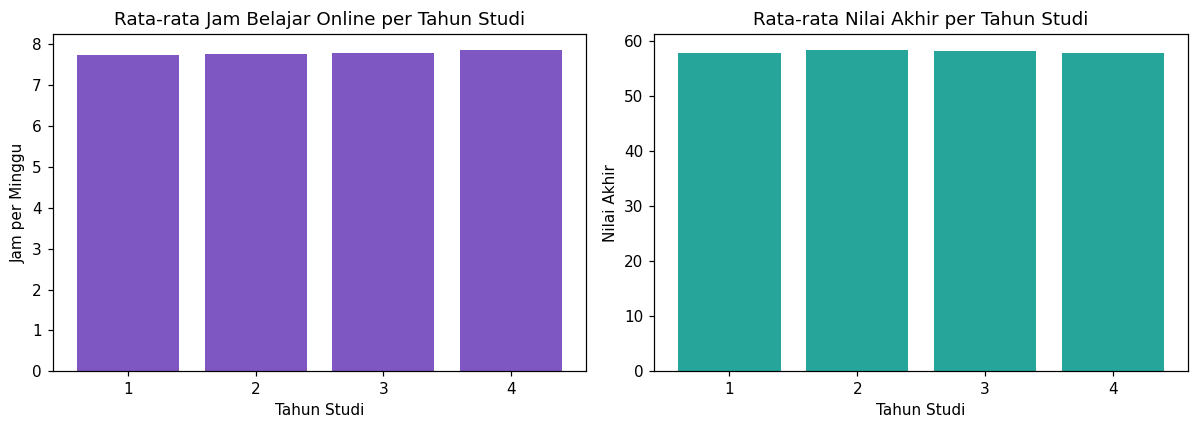

In [19]:
rata = df.groupby("Course_Year")[["Online_Learning_Hours",
                                  "Final_Academic_Score"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(rata.index.astype(str), rata["Online_Learning_Hours"],
          color="#7e57c2")
ax[0].set_title("Rata-rata Jam Belajar Online per Tahun Studi")
ax[0].set_xlabel("Tahun Studi")
ax[0].set_ylabel("Jam per Minggu")
ax[1].bar(rata.index.astype(str), rata["Final_Academic_Score"],
          color="#26a69a")
ax[1].set_title("Rata-rata Nilai Akhir per Tahun Studi")
ax[1].set_xlabel("Tahun Studi")
ax[1].set_ylabel("Nilai Akhir")
plt.tight_layout()
plt.savefig("viz_04_rata_per_tahun.png")
plt.show()